In [1]:
import dcm2niix
import zipfile
import tempfile
from pathlib import Path

In [5]:
def dcm2niix_from_zip(path, args):
    zf = zipfile.ZipFile(path)
    with tempfile.TemporaryDirectory() as tempdir:
        with zipfile.ZipFile(path) as zf:
            print(tempdir)
            zf.extractall(tempdir)
            return dcm2niix.main(args + [tempdir])

In [ ]:
dcm2niix_from_zip('QA_FMRI_2025-10-07a.zip', '-d 9 -r y -o data'.split())

In [7]:
dcm2niix_from_zip('QA_FMRI_2025-10-07a.zip', '-d 9 -o data -i y -f %p_%s -z y'.split())

/tmp/tmp4yhkbdtd
Chris Rorden's dcm2niiX version v1.0.20250505  GCC10.2.1 x86-64 (64-bit Linux)
Found 1757 DICOM file(s)
Ignoring localizer (sequence 'fl2d1') of series 6 /tmp/tmp4yhkbdtd/QA_FMRI_2025-10-07a/MRI/Yellow/QA_FMRI_2025-10-07/PHANTOM_EZFMRI_EZFMRI/__20251007_173924_756000/NOISECOVARIANCE_0006/PHANTOM_EZFMRI.MR._.0006.0001.2025.10.07.18.19.39.694639.56006418.IMA
Convert 200 DICOM as data/FBIRN_QA_fMRI_flip77_14 (64x64x30x200)
Compress: "/usr/bin/pigz" -b 960 --no-time -n -f -6 "data/FBIRN_QA_fMRI_flip77_14.nii"
Ignoring localizer (sequence 'fl2d1') of series 4 /tmp/tmp4yhkbdtd/QA_FMRI_2025-10-07a/MRI/Yellow/QA_FMRI_2025-10-07/PHANTOM_EZFMRI_EZFMRI/__20251007_173924_756000/GFACTOR_0004/PHANTOM_EZFMRI.MR._.0004.0001.2025.10.07.18.19.39.694639.56005934.IMA
Convert 200 DICOM as data/FBIRN_QA_fMRI_flip77_13 (64x64x30x200)
Compress: "/usr/bin/pigz" -b 960 --no-time -n -f -6 "data/FBIRN_QA_fMRI_flip77_13.nii"
Convert 7 DICOM as data/ABCD_QA_dMRI_17 (140x140x81x7)
Compress: "/usr/bi

0

In [29]:
import nibabel as nib

img = nib.load("data/FBIRN_QA_fMRI_flip77_13.nii.gz")
img

<OrthoSlicer3D: data/FBIRN_QA_fMRI_flip77_13.nii.gz (64, 64, 30, 200)>

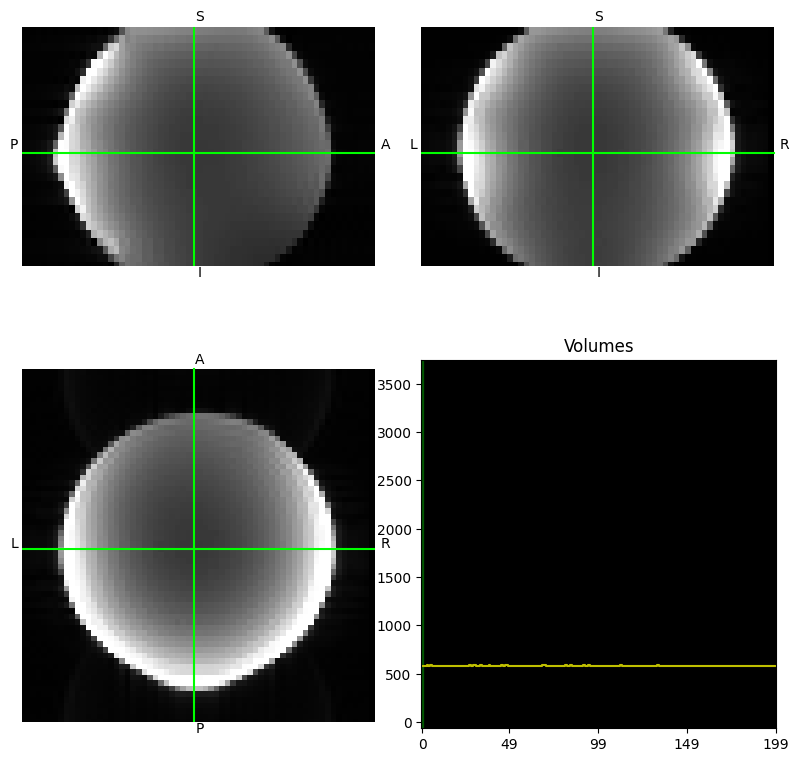

In [2]:
#%matplotlib ipympl
n.orthoview()

In [5]:
image_data = n.get_fdata()

In [6]:
image_data.shape

(64, 64, 30, 200)

In [7]:
image_data.flags

  C_CONTIGUOUS : False
  F_CONTIGUOUS : True
  OWNDATA : True
  WRITEABLE : True
  ALIGNED : True
  WRITEBACKIFCOPY : False

In [10]:
other = np.ascontiguousarray(image_data)

In [9]:
import numpy as np

In [12]:
other.flags

  C_CONTIGUOUS : True
  F_CONTIGUOUS : False
  OWNDATA : True
  WRITEABLE : True
  ALIGNED : True
  WRITEBACKIFCOPY : False

In [13]:
image_data.shape

(64, 64, 30, 200)

In [14]:
other.shape

(64, 64, 30, 200)

In [24]:
w = other.mean(axis=-1)
s = other.std(axis=-1)
t = w/s
t[s==0] = 0

/tmp/ipykernel_1363910/83052951.py:3: RuntimeWarning: invalid value encountered in divide
  t = w/s


In [25]:
w.shape

(64, 64, 30)

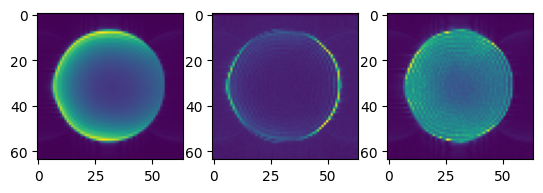

In [26]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1,3)
ax[0].imshow(w[:,:,15])
ax[1].imshow(s[:,:,15])
ax[2].imshow(t[:,:,15])